# Day 3 — Classic Models, Tuning & Keeping Records (HDFS logs)

**Project:** Automatic Incident & Log Agent. Same table and the same time split as Day 2 (`logagent.splits`).

**Task: early warning.** Predict whether a block will fail using only its **first 8 log events**
(about 40% of a typical block's lifetime), so the agent can warn *before* the failure is obvious.

0. Why not use the full-lifetime counts? (they make the problem too easy)
1. Baselines (dummy, logistic regression, random forest)
2. LightGBM with early stopping
3. Feature importance + SHAP
4. Optuna sweep, every trial logged to MLflow
5. Register the best model; reproducibility check

Open the MLflow UI afterwards from the repo root: `uv run mlflow ui --backend-store-uri sqlite:///mlflow.db`

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import lightgbm as lgb, shap, optuna, mlflow
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score

from logagent.splits import load_blocks, time_split, xy, FEATURES, EARLY_FEATURES, ROOT

SEED = 42
train, val, test = time_split(load_blocks())
X_tr, y_tr = xy(train, EARLY_FEATURES); X_va, y_va = xy(val, EARLY_FEATURES); X_te, y_te = xy(test, EARLY_FEATURES)

mlflow.set_tracking_uri(f"sqlite:///{ROOT / 'mlflow.db'}")
mlflow.set_experiment("day3-hdfs-anomaly")
pr_auc = lambda y, p: average_precision_score(y, p)
print(len(X_tr), len(X_va), len(X_te))

2026/10/14 17:30:59 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/14 17:30:59 INFO mlflow.store.db.utils: Updating database tables


2026/10/14 17:31:04 INFO mlflow.tracking.fluent: Experiment with name 'day3-hdfs-anomaly' does not exist. Creating a new experiment.


402542 86259 86260


## 0. Why early warning?
With counts over a block's *whole* lifetime, LightGBM separates anomalies almost perfectly. By then the failure has
already happened, so a perfect score there isn't useful for alerting.

In [2]:
full = lgb.LGBMClassifier(n_estimators=300, random_state=SEED, verbose=-1).fit(*xy(train, FEATURES))
Xv_full, yv_full = xy(val, FEATURES)
print(f"full-lifetime features -> val PR-AUC = {pr_auc(yv_full, full.predict_proba(Xv_full)[:, 1]):.4f}  (too easy)")

full-lifetime features -> val PR-AUC = 1.0000  (too easy)


## 1. Baselines
A model only "works" if it beats something simple. Every run is logged.

In [3]:
baselines = {
    "dummy_prior": DummyClassifier(strategy="prior"),
    "logreg": Pipeline([("prep", ColumnTransformer([("num", Pipeline([("log", FunctionTransformer(np.log1p)), ("sc", StandardScaler())]), EARLY_FEATURES)])),
                        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "random_forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced", n_jobs=-1, random_state=SEED),
}
base_scores = {}
for name, model in baselines.items():
    with mlflow.start_run(run_name=name):
        model.fit(X_tr, y_tr)
        base_scores[name] = pr_auc(y_va, model.predict_proba(X_va)[:, 1])
        mlflow.log_param("model", name)
        mlflow.log_metric("val_pr_auc", base_scores[name])
pd.Series(base_scores, name="val PR-AUC").round(4)

dummy_prior      0.0302
logreg           0.3996
random_forest    0.4357
Name: val PR-AUC, dtype: float64

## 2. LightGBM with early stopping
Gradient-boosted trees: each new tree fixes the previous trees' mistakes. Early stopping halts when validation PR-AUC
stops improving, so we don't pick the number of trees by hand (and don't overfit).

In [4]:
params = dict(objective="binary", learning_rate=0.05, num_leaves=31, min_child_samples=20,
              n_estimators=2000, random_state=SEED, deterministic=True, verbose=-1)
with mlflow.start_run(run_name="lgbm_default"):
    lgbm = lgb.LGBMClassifier(**params)
    lgbm.fit(X_tr, y_tr, eval_X=X_va, eval_y=y_va, eval_metric="average_precision",
             callbacks=[lgb.early_stopping(100, verbose=False)])
    lgbm_score = pr_auc(y_va, lgbm.predict_proba(X_va)[:, 1])
    mlflow.log_params({k: v for k, v in params.items() if k != "n_estimators"})
    mlflow.log_metrics({"val_pr_auc": lgbm_score, "best_iteration": lgbm.best_iteration_})
print(f"best_iteration={lgbm.best_iteration_}  val PR-AUC={lgbm_score:.4f}  (best baseline {max(base_scores.values()):.4f})")

best_iteration=106  val PR-AUC=0.4389  (best baseline 0.4357)


## 3. Explainability: feature importance and SHAP

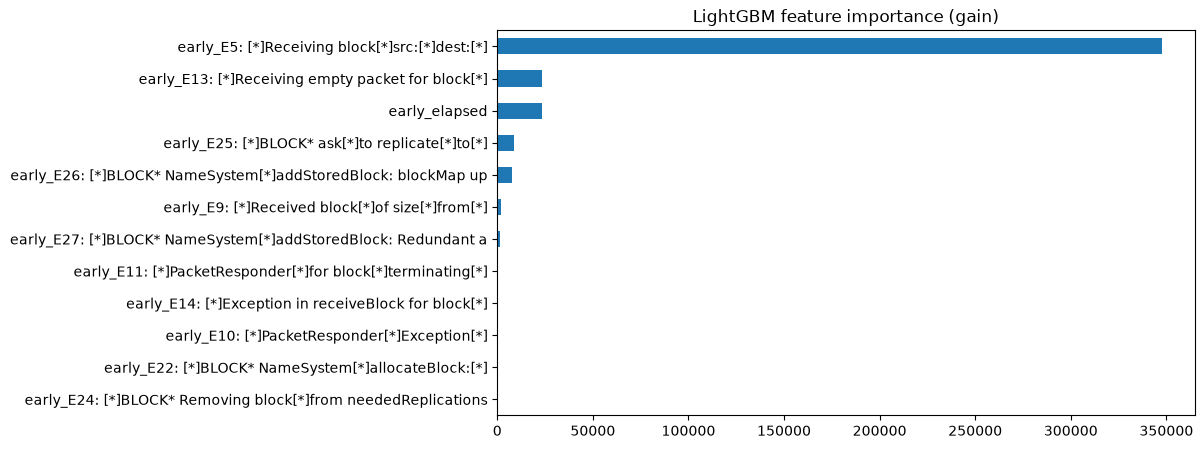

In [5]:
templates = pd.read_csv(ROOT / "data/raw/preprocessed/HDFS.log_templates.csv").set_index("EventId")["EventTemplate"]
label = lambda f: f"{f}: {templates[f.removeprefix('early_')][:50]}" if f.removeprefix("early_") in templates else f
imp = pd.Series(lgbm.booster_.feature_importance("gain"), index=EARLY_FEATURES).sort_values().tail(12)
imp.index = [label(f) for f in imp.index]
imp.plot.barh(figsize=(9, 5), title="LightGBM feature importance (gain)");

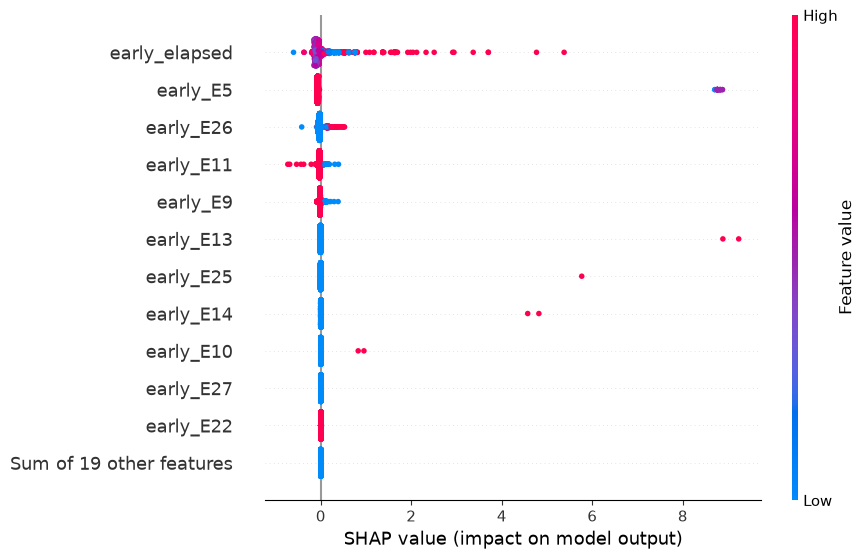

In [6]:
explainer = shap.TreeExplainer(lgbm)
sample = X_va.sample(3000, random_state=SEED)
sv = explainer(sample)
shap.plots.beeswarm(sv, max_display=12)

block: blk_-4890637624398498024  p(anomaly)= 0.9996


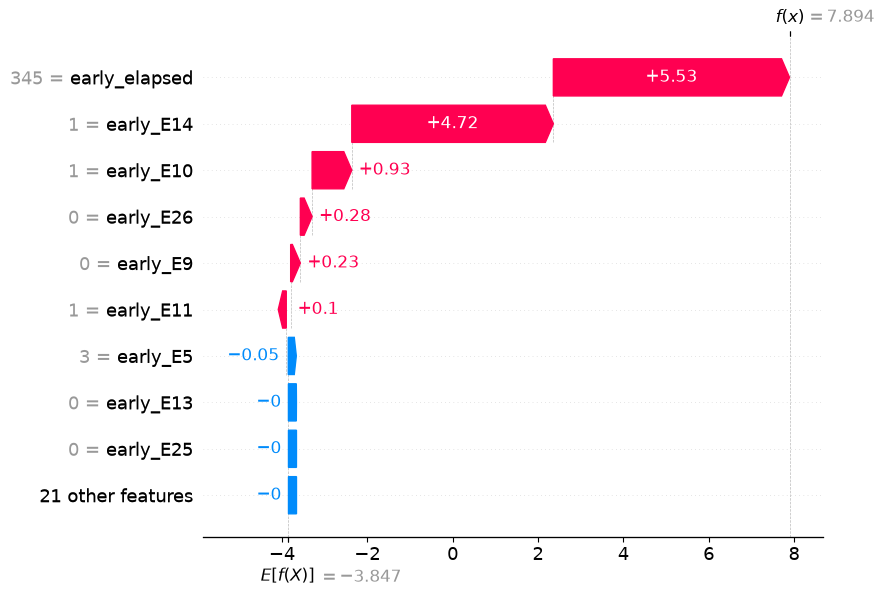

In [7]:
# Explain one anomaly the model flagged: which events pushed it towards "anomaly"?
p_va = lgbm.predict_proba(X_va)[:, 1]
idx = int(np.argmax(np.where(y_va.values == 1, p_va, -1)))
one = explainer(X_va.iloc[[idx]])
print("block:", val.iloc[idx]["block_id"], " p(anomaly)=", round(p_va[idx], 4))
shap.plots.waterfall(one[0], max_display=10)

## 4. Hyperparameter tuning with Optuna + MLflow
Hyperparameters are settings *we* choose (tree size, learning rate…); weights are what training learns.
Each Optuna trial is a nested MLflow run. Tuning uses **validation** only — test stays untouched.

In [8]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    p = dict(objective="binary", n_estimators=2000, random_state=SEED, deterministic=True, verbose=-1,
             learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
             num_leaves=trial.suggest_int("num_leaves", 8, 128, log=True),
             min_child_samples=trial.suggest_int("min_child_samples", 5, 200, log=True),
             subsample=trial.suggest_float("subsample", 0.5, 1.0), subsample_freq=1,
             colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
             reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
             scale_pos_weight=trial.suggest_float("scale_pos_weight", 1, 30, log=True))
    with mlflow.start_run(run_name=f"trial_{trial.number}", nested=True):
        m = lgb.LGBMClassifier(**p)
        m.fit(X_tr, y_tr, eval_X=X_va, eval_y=y_va, eval_metric="average_precision",
              callbacks=[lgb.early_stopping(100, verbose=False)])
        score = pr_auc(y_va, m.predict_proba(X_va)[:, 1])
        mlflow.log_params(trial.params)
        mlflow.log_metrics({"val_pr_auc": score, "best_iteration": m.best_iteration_})
    trial.set_user_attr("best_iteration", m.best_iteration_)
    return score

with mlflow.start_run(run_name="optuna_sweep"):
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=25)
    mlflow.log_params({f"best_{k}": v for k, v in study.best_params.items()})
    mlflow.log_metric("best_val_pr_auc", study.best_value)
print(f"best val PR-AUC={study.best_value:.4f}  params={study.best_params}")

best val PR-AUC=0.4400  params={'learning_rate': 0.03471445832379457, 'num_leaves': 23, 'min_child_samples': 72, 'subsample': 0.5214658685003697, 'colsample_bytree': 0.9106923054944556, 'reg_lambda': 0.0014139508157722993, 'scale_pos_weight': 1.580206338573197}


## 5. Final model: refit with the best params, test once, register in MLflow

In [9]:
best = dict(objective="binary", random_state=SEED, deterministic=True, verbose=-1, subsample_freq=1,
            n_estimators=study.best_trial.user_attrs["best_iteration"], **study.best_params)

def fit_final():
    return lgb.LGBMClassifier(**best).fit(X_tr, y_tr)

with mlflow.start_run(run_name="lgbm_final") as run:
    final = fit_final()
    val_s, test_s = pr_auc(y_va, final.predict_proba(X_va)[:, 1]), pr_auc(y_te, final.predict_proba(X_te)[:, 1])
    mlflow.log_params(best)
    mlflow.log_metrics({"val_pr_auc": val_s, "test_pr_auc": test_s})
    mlflow.lightgbm.log_model(final.booster_, name="model", registered_model_name="hdfs-anomaly-lgbm",
                              input_example=X_va.head(5))
print(f"val PR-AUC={val_s:.4f}  test PR-AUC={test_s:.4f}  run_id={run.info.run_id}")

/home/hp/Projects/Test-Project/ml-learning/.venv/lib/python3.13/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


2026/10/14 17:32:55 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


val PR-AUC=0.4400  test PR-AUC=0.8373  run_id=e9fa1448f6d343ee8dcc48c30227e67e


Successfully registered model 'hdfs-anomaly-lgbm'.
Created version '1' of model 'hdfs-anomaly-lgbm'.


In [10]:
# Reproducibility: same data + params + seed -> identical predictions
again = fit_final()
print("identical predictions:", np.array_equal(final.predict_proba(X_te), again.predict_proba(X_te)))

identical predictions: True


In [11]:
summary = pd.Series({**base_scores, "lgbm_default": lgbm_score, "lgbm_tuned (val)": val_s, "lgbm_tuned (TEST)": test_s}, name="PR-AUC")
summary.round(4)

dummy_prior          0.0302
logreg               0.3996
random_forest        0.4357
lgbm_default         0.4389
lgbm_tuned (val)     0.4400
lgbm_tuned (TEST)    0.8373
Name: PR-AUC, dtype: float64

**Reading the results:** early warning is genuinely harder than classifying a finished block. Watch the
validation-vs-test gap too: the test period has a different anomaly rate (Day 2 EDA), which is a first taste of the
drift you'll monitor on Day 11. Day 4 adds calibration, a cost-based alert threshold, and error slices.

## End-of-day checklist
- [x] Tuned LightGBM beats the baselines (on validation, confirmed once on test)
- [x] SHAP explanation of what drives predictions
- [x] Every run logged in MLflow; best model registered as `hdfs-anomaly-lgbm`
- [x] Reproducible from saved params + seed